# Waveguide fluorescence：同步 A/B、時間波形、逐 shot 模式

此 notebook 預設只跑合成資料，不連硬體。選 labberenv kernel；從 Qawg-main 開啟。
ADC A 是訊號，B 是獨立 coherent pilot。保留每個 shot；不把 emission 自己轉成正相位。
FIR 預設通帶 30 MHz、阻帶 70 MHz（50 MHz IF）。不是通用校正值，先用 loopback 驗證。
詳細改動見 `docs/WAVEGUIDE_UPGRADE_NOTES.md`。

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'QAWG').is_dir())
sys.path.insert(0, str(ROOT))
from QAWG.alazar import IFProcessor, reference_phase_correct, save_mode_shots
from QAWG.tomography import project_temporal_mode
processor = IFProcessor(sample_rate_hz=1e9, if_hz=50e6,
                        passband_hz=30e6, stopband_hz=70e6, taps=181)
print(processor.response_summary())

{'passband_error_db': 0.0004456562778620569, 'stopband_attenuation_db': 83.3436439862785}


## 1. 已知 30 MHz envelope + 獨立 reference

這是 classical DSP 驗證，不是單光子態模擬。兩路共用技術相位漂移，但 A 另有已知 intrinsic phase。

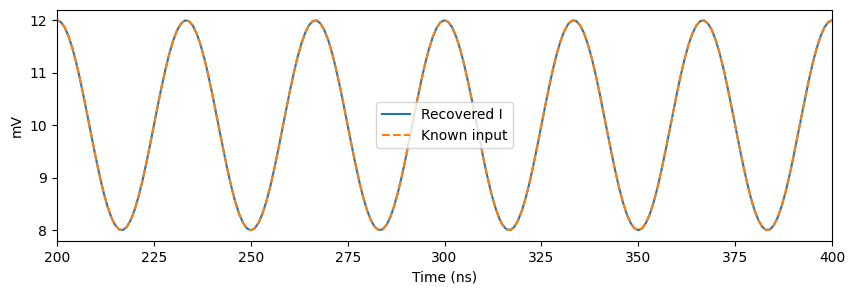

In [2]:
rng = np.random.default_rng(10)
shots, count = 128, 2048
time_s = np.arange(count) / processor.sample_rate_hz
technical_phase = rng.uniform(-np.pi, np.pi, shots)
intrinsic_phase = np.linspace(-1.0, 1.0, shots)
envelope = 0.01 * (1 + 0.2 * np.cos(2*np.pi*30e6*time_s))
carrier = 2*np.pi*processor.if_hz*time_s
raw_a = envelope[None,:] * np.cos(carrier[None,:] + technical_phase[:,None] + intrinsic_phase[:,None])
raw_b = 0.05 * np.cos(carrier[None,:] + technical_phase[:,None])
iq_a, iq_b = processor.process(raw_a), processor.process(raw_b)
corrected, phases = reference_phase_correct(iq_a, iq_b, (200, 600), min_reference_amplitude=0.01)
valid = slice(processor.edge_samples, -processor.edge_samples)
expected = envelope[None,:] * np.exp(1j*intrinsic_phase[:,None])
np.testing.assert_allclose(corrected[:,200:-200], expected[:,200:-200], atol=1e-6)
fig, ax = plt.subplots(figsize=(10,3))
ax.plot(time_s[valid]*1e9, corrected[shots//2,valid].real*1e3, label='Recovered I')
ax.plot(time_s[valid]*1e9, expected[shots//2,valid].real*1e3, '--', label='Known input')
ax.set(xlim=(200,400), xlabel='Time (ns)', ylabel='mV'); ax.legend(); plt.show()

## 2. 固定 mode，保留所有 shots

Mode 只在 FIR guard 外非零，L2 normalization 是離散電壓投影的 convention，還不是 photon units。
真正 emission 應用獨立 calibration data 定義固定 mode；不要隨每個 shot 調整。

In [3]:
weights = np.zeros(count, dtype=complex)
weights[300:1400] = np.exp(-np.arange(1100)/(2*250))
weights /= np.linalg.norm(weights)
mode_iq = project_temporal_mode(corrected, weights)
print('Full IQ:', corrected.shape, 'Mode samples:', mode_iq.shape)
assert mode_iq.shape == (shots,)
# mean field 與 mean intensity 是不同物理量。
mean_field = corrected.mean(axis=0)
measured_intensity = np.mean(abs(corrected)**2, axis=0)

Full IQ: (128, 2048) Mode samples: (128,)


In [4]:
# Optional save: never overwrites. Use a new filename for each condition/block.
SAVE = False
if SAVE:
    save_mode_shots(ROOT / 'waveguide_mode_demo.hdf5', iq_shots=corrected,
                    time_s=time_s, weights=weights, processor=processor,
                    reference_phase=phases,
                    metadata={'condition':'synthetic DSP verification', 'photon_calibrated':False})

## 3. 真實硬體：擇一入口

先完成接線、時脈、兩通道 gain、trigger 與 pulse 上傳。B 必須是高 SNR 獨立 reference；以下時間窗和 threshold 只是待校正範例。
不改既有單通道方法。新方法回傳完整 (shot, sample) corrected IQ，capture 保留 (shot, A/B, sample) 原始資料。

已有 `experiment`（AWGAlazar）的情況，可設定下方開關。此入口不重排 sweep steps，須自行保留 sequence labels；不做 baseline／time averaging。


In [5]:
RUN_HARDWARE = False
if RUN_HARDWARE:
    # experiment must already be configured with the intended AWG program.
    capture, signal_iq, pilot_phases = experiment.acquire_referenced_waveforms(
        1000, processor=processor, reference_window_samples=(200, 600),
        min_reference_amplitude=0.01)
    a = capture.channel_records(1)
    b = capture.channel_records(2)
    print(capture.channels, a.shape, b.shape)
    # Define time_s/mode weights for THIS capture length before save_mode_shots.


也可使用低階 `Alazar9371`：`configure(channel=3, use_external_10mhz_reference=True)`，再以 `CaptureConfig(samples_per_record=2048, records_per_acquisition=1000, channel=3)` 擷取。3 是 A|B mask，不是第 3 channel。啟動順序必須 ADC armed/start → AWG marker。

## 4. Tomography 邊界

正式量測交錯保存 signal、vacuum、coherent calibration blocks。`mode_iq` 仍是 volts projection。
`heterodyne_ml_density_matrix` 是 ideal heterodyne 模型，尚未含你的 added-noise/loss calibration；不能把 noise RMS normalize 後的 HEMT 資料當作已校正 photon samples。本次沒有宣稱完成 noisy-chain tomography。
完整原始分布、mode、FIR coefficients、gain/reference plane、phase correction 與 shots metadata 都要保存。